# 05 · Modelos lineales: OLS hedónico, Ridge, Lasso y ElasticNet

**Proyecto:** Predicción del precio de vivienda con aprendizaje automático (UAO · Aprendizaje Automático · 2026-2)
**Tarjeta de Trello:** `T19` · Modelos lineales (OLS hedónico, Ridge, Lasso, ElasticNet)
**Responsable:** Brandon Eduardo Tobar Sánchez (Model Developer · Evaluation Lead) · **Revisa:** Juan Miguel León Gómez
**Objetivo:** implementar y ajustar los cuatro modelos lineales con **validación cruzada interna**, sobre los preprocesamientos **P1 y P2**, e interpretar sus coeficientes. Atiende el objetivo específico 3 de T04 (comparar modelos) y prepara la comparación final de T22.

**Contenido**
1. Preparación del entorno
2. Configuración y semilla
3. Carga del entrenamiento y aislamiento del test sellado
4. Diseño: modelos, preprocesamientos y búsqueda de hiperparámetros
5. Línea base hedónica con inferencia (conexión con Inferencia Estadística)
6. Búsqueda de hiperparámetros
7. Resultados por modelo y preprocesamiento
8. Figuras
9. Interpretación de los coeficientes
10. Limitaciones
11. Conclusiones de desarrollo
12. Reproducción

> **Estado de P3: pendiente.** Mauricio prepara una corrección de P3 (conservar las variables derivadas de T18 y retirar la selección por información mutua con k = 10). Hasta que esté integrada en `main`, este notebook **no evalúa P3** y no implementa una versión propia. Cuando se fusione, basta con agregar `"P3"` a `PREPROCESAMIENTOS_T19` y volver a ejecutar.

> **Estos resultados son de desarrollo.** El mejor puntaje de cada búsqueda es **optimista** (se eligió el mejor entre muchos candidatos con los mismos pliegues con que se mide). No son estimaciones finales independientes ni declaran un ganador: la comparación definitiva con validación anidada es de T22 y el test sellado se abre solo en T25.

## 1. Preparación del entorno

Igual que en la plantilla: en **Colab** clona el repositorio e instala las dependencias; en **local** ubica la raíz para importar `src/`.

In [1]:
# --- Preparación del entorno (Colab o local) ---
import os
import subprocess
import sys
from pathlib import Path

EN_COLAB = "google.colab" in sys.modules  # True si el notebook corre en Google Colab

if EN_COLAB:
    url = "https://github.com/Juanm0331123/ml-precio-vivienda.git"  # repositorio público
    if not Path("ml-precio-vivienda").exists():
        subprocess.run(["git", "clone", "-q", url], check=True)
    os.chdir("ml-precio-vivienda")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)

RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))
print("Raíz del proyecto:", RAIZ)

Raíz del proyecto: C:\Users\Windows 11\Desktop\ml-precio-vivienda


## 2. Configuración y semilla

Se usa la semilla global **5007** y los mismos 15 pliegues del piloto (T12: validación repetida 5 × 3, estratificada por quintiles del precio de entrenamiento). Se registran versiones y equipo.

In [2]:
import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from src.busqueda import ejecutar_busqueda, entorno, fila_mejor, tabla_candidatos
from src.config import DIR_FIGURAS, DIR_TABLAS, RUTA_DATOS_CRUDOS, SEMILLA, SHA256_DATOS_CRUDOS
from src.evaluacion import FACTOR_KAGGLE, cargar_entrenamiento, crear_pliegues, huella_sha256
from src.modelos_lineales import (ESPACIOS, MODELOS_LINEALES, PREFIJO, PREPROCESAMIENTOS_T19, construir_pipeline_lineal,
                                  diagnostico_convergencia, ols_hedonico_statsmodels, tabla_coeficientes)

warnings.filterwarnings("ignore", category=FutureWarning)
np.random.seed(SEMILLA)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
DIR_FIGURAS.mkdir(parents=True, exist_ok=True)
DIR_TABLAS.mkdir(parents=True, exist_ok=True)

ENTORNO = entorno({"tarjeta": "T19"})
pd.Series(ENTORNO, name="valor").to_frame()

,valor
python,3.13.14
sistema,Windows 11
procesador,"AMD64 Family 25 Model 97 Stepping 2, AuthenticAMD"
nucleos_logicos,12
numpy,2.5.2
pandas,3.0.5
scipy,1.18.1
scikit-learn,1.9.1
semilla,5007
xgboost,3.4.1


## 3. Carga del entrenamiento y aislamiento del test sellado

`cargar_entrenamiento()` carga **solo las 436 filas de entrenamiento** de T06 (salta las líneas de `prueba` al leer): los valores del test nunca entran a memoria. Se verifica además que los archivos de datos no cambiaron.

In [3]:
X, y, evidencia = cargar_entrenamiento()
assert evidencia["n_entrenamiento_cargado"] == 436 and evidencia["n_prueba_cargado"] == 0
assert huella_sha256(RUTA_DATOS_CRUDOS) == SHA256_DATOS_CRUDOS

pliegues = crear_pliegues(y)   # 15 pliegues (5 × 3), los mismos del piloto T12
assert len(pliegues) == 15 and all(len(set(a) & set(v)) == 0 for a, v in pliegues)

print(f"Filas de entrenamiento: {len(X)} | filas de prueba cargadas: {evidencia['n_prueba_cargado']} | pliegues: {len(pliegues)}")
print(f"Escala de price: unidades de Kaggle = dólares canadienses de 1987 × {FACTOR_KAGGLE} (no son precios actuales ni pesos colombianos)")
print("SHA-256 particion.csv:", evidencia["sha256_particion"])
X.head(3)

Filas de entrenamiento: 436 | filas de prueba cargadas: 0 | pliegues: 15
Escala de price: unidades de Kaggle = dólares canadienses de 1987 × 70 (no son precios actuales ni pesos colombianos)
SHA-256 particion.csv: 7c34c251279e7f15b21853d58b37f953f37d56f7aead93a3ef99c50d24013f1f


,area,bedrooms,bathrooms,stories,parking,mainroad,guestroom,basement,hotwaterheating,airconditioning,prefarea,furnishingstatus
id,,,,,,,,,,,,
0,7420,4,2,3,2,1,0,0,0,1,1,2
2,9960,3,2,2,2,1,0,1,0,0,1,1
3,7500,4,2,2,3,1,0,1,0,1,1,2


## 4. Diseño: modelos, preprocesamientos y búsqueda

| Modelo | Qué es | Hiperparámetros que se buscan |
|---|---|---|
| **OLS** | Regresión hedónica sin penalización: línea base | ninguno |
| **Ridge** | Penalización L2: encoge los coeficientes y estabiliza con atributos correlacionados | `alpha` |
| **Lasso** | Penalización L1: además puede llevar coeficientes exactamente a 0 (selección) | `alpha` |
| **ElasticNet** | Mezcla de L1 y L2 | `alpha` y `l1_ratio` |

**Preprocesamientos (de T12, T17 y T18, sin modificarlos).** P1 y P2, con `furnishingstatus` como nominal (*one-hot*). OLS no escala las predictoras (sus predicciones no dependen de la escala y los coeficientes quedan en unidades naturales); los modelos penalizados sí, porque la penalización depende de la escala de cada variable. **Todo se ajusta dentro del pliegue.**

**Escala del objetivo en los penalizados.** Ridge, Lasso y ElasticNet estandarizan el objetivo dentro del pliegue (en P2, primero `log`). Así `alpha` significa lo mismo en P1 (precio del orden de 10⁶) y en P2 (log-precio): sin eso, ninguna rejilla de `alpha` serviría para las dos. Para OLS y Ridge no cambia las predicciones (la solución escala con el objetivo; hay una prueba automática). Las métricas siempre se calculan en la **escala original** de `price`, porque `TransformedTargetRegressor` invierte la transformación antes de devolver predicciones.

**Búsqueda.** Rejilla explícita, con CV interna en los 15 pliegues; el criterio de selección es el **RMSE** de validación. Se guardan **todos** los candidatos probados. **Convergencia:** Lasso y ElasticNet usan descenso por coordenadas con un tope muy alto de iteraciones (200.000) y se verifica que el modelo final lo haya terminado antes del tope y que no haya avisos de convergencia.

In [4]:
resumen_rejillas = pd.DataFrame([
    {"modelo": n, "descripción": MODELOS_LINEALES[n][0], "rejilla": {k.replace(PREFIJO, ""): (f"{len(v)} valores en [{min(v):.0e}, {max(v):.0e}]" if len(v) > 8 else v) for k, v in ESPACIOS[n].items()} or "sin hiperparámetros",
     "candidatos": int(np.prod([len(v) for v in ESPACIOS[n].values()])) if ESPACIOS[n] else 1}
    for n in MODELOS_LINEALES
])
resumen_rejillas

,modelo,descripción,rejilla,candidatos
0,OLS,"OLS hedónico (línea base, sin penalización)",sin hiperparámetros,1
1,Ridge,Ridge (penalización L2),"{'alpha': '25 valores en [1e-03, 1e+03]'}",25
2,Lasso,Lasso (penalización L1),"{'alpha': '31 valores en [1e-06, 1e+00]'}",31
3,ElasticNet,ElasticNet (L1 + L2),"{'alpha': '20 valores en [1e-04, 1e+00]', 'l1_...",180


## 5. Línea base hedónica con inferencia (conexión con Inferencia Estadística)

**Qué se hace.** Se ajusta el modelo hedónico clásico con `statsmodels` solo con las 436 filas de entrenamiento, en dos formas: precio (lineal) y log-precio (log-lineal), la misma pareja de modelos del curso de Inferencia Estadística (T04, 1.8). Da errores estándar y valores p, algo que el pipeline de predicción no entrega.

**Por qué.** OLS es la línea base de este proyecto y su lectura natural es la hedónica: cada coeficiente es el precio implícito de un atributo [Rosen, 1974]. Aquí se usa para **interpretar**, no para seleccionar modelos.

**Cómo leerlo.** Los R² son **dentro de muestra**; T04 reportó R² ajustado de 67,4 % (lineal) y 69,2 % (log-lineal) con las 545 filas y su propia codificación, de modo que **no son comparables uno a uno** con estos (436 filas). Sirven como orden de magnitud.

In [5]:
tabla_lin, res_lin = ols_hedonico_statsmodels(X, y, logaritmico=False)
tabla_log, res_log = ols_hedonico_statsmodels(X, y, logaritmico=True)
pd.DataFrame([{"modelo": "lineal (precio)", **res_lin}, {"modelo": "log-lineal (log precio)", **res_log}]).round(4)

,modelo,n,r2,r2_ajustado
0,lineal (precio),436,0.6734,0.6634
1,log-lineal (log precio),436,0.6924,0.6829


In [6]:
tabla_log.to_csv(DIR_TABLAS / "t19_ols_hedonico_inferencia.csv", index=False)
vista = tabla_log.copy()
vista["significativo (p<0,05)"] = np.where(vista["valor_p"] < 0.05, "sí", "no")
b_area = float(tabla_log.loc[tabla_log["variable"] == "area", "coeficiente"].iloc[0])
display(Markdown(f"*area* está en pies cuadrados, por eso su coeficiente por unidad es minúsculo: **+1.000 pies² de lote se asocian con {100 * (np.exp(1000 * b_area) - 1):+.1f} %** del precio (log-lineal, demás variables constantes)."))
vista.round(4)

*area* está en pies cuadrados, por eso su coeficiente por unidad es minúsculo: **+1.000 pies² de lote se asocian con +4.8 %** del precio (log-lineal, demás variables constantes).

,variable,coeficiente,error_estandar,valor_p,ic95_inferior,ic95_superior,cambio_pct,"significativo (p<0,05)"
0,intercepto,14.2324,0.0529,0.0000,14.1284,14.3363,NaN,sí
1,area,0.0000,0.0000,0.0000,0.0000,0.0001,0.0047,sí
2,bedrooms,0.0376,0.0164,0.0227,0.0053,0.0699,3.8317,sí
3,bathrooms,0.1668,0.0235,0.0000,0.1207,0.2130,18.1559,sí
4,stories,0.0880,0.0142,0.0000,0.0601,0.1159,9.1957,sí
5,parking,0.0498,0.0130,0.0002,0.0241,0.0754,5.1012,sí
6,mainroad,0.1130,0.0318,0.0004,0.0505,0.1755,11.9657,sí
7,guestroom,0.0647,0.0301,0.0321,0.0055,0.1239,6.6842,sí
8,basement,0.0841,0.0240,0.0005,0.0371,0.1312,8.7780,sí
9,hotwaterheating,0.1862,0.0470,0.0001,0.0938,0.2786,20.4699,sí


**Lectura de la tabla log-lineal.** Con el logaritmo del precio como objetivo, un coeficiente `β` aproxima un cambio de `100·(exp(β) − 1)` % en el precio por cada **unidad** de la variable, manteniendo las demás constantes (columna `cambio_pct`). Es una **asociación condicional** del modelo, no un efecto causal: con atributos correlacionados el reparto entre variables es inestable, y `furnishingstatus` fue agregada en Kaggle sin documentar. Los valores p describen esta muestra; **no** se usan para elegir modelos.

## 6. Búsqueda de hiperparámetros

**Qué se hace.** Para cada preprocesamiento (P1, P2) y cada modelo, se evalúan todos los candidatos de la rejilla en los mismos 15 pliegues, y se reajusta el mejor con las 436 filas para extraer coeficientes y revisar la convergencia. **Si algo falla** se detiene con el error (no se reemplaza por ceros).

In [7]:
import time

resultados, candidatos, coeficientes, per_fold = [], [], [], {}
estimadores_finales = {}
t_total = time.perf_counter()
for p in PREPROCESAMIENTOS_T19:
    for nombre in MODELOS_LINEALES:
        r = ejecutar_busqueda(construir_pipeline_lineal(p, nombre), ESPACIOS[nombre], X, y, pliegues, tipo="grid", n_jobs=1)
        b = r["busqueda"]
        fila = fila_mejor(b, p, nombre, r["duracion_s"], r["n_candidatos"])
        final = b.best_estimator_                                    # reajustado con las 436 filas
        coef = tabla_coeficientes(final, X, p, nombre)
        conv = diagnostico_convergencia(final, nombre)
        fila.update({"avisos_convergencia": r["avisos_convergencia"], "n_variables": len(coef), "n_coef_nulos": int(coef["coef_nulo"].sum()),
                     "n_iter": conv["n_iter"], "convergio": conv["convergio"]})
        resultados.append(fila); coeficientes.append(coef); candidatos.append(tabla_candidatos(b, p, nombre))
        per_fold[(p, nombre)] = np.array([-b.cv_results_[f"split{k}_test_rmse"][b.best_index_] for k in range(len(pliegues))])
        estimadores_finales[(p, nombre)] = final
print(f"Búsquedas terminadas en {time.perf_counter() - t_total:.1f} s | combinaciones: {len(resultados)} | candidatos probados: {sum(len(c) for c in candidatos)}")

resultados = pd.DataFrame(resultados)
candidatos = pd.concat(candidatos, ignore_index=True)
coeficientes = pd.concat(coeficientes, ignore_index=True)

# Controles de calidad: convergencia y números finitos
assert resultados["avisos_convergencia"].fillna(0).eq(0).all(), "Hay avisos de convergencia"
assert resultados.loc[resultados["modelo"].isin(["Lasso", "ElasticNet"]), "convergio"].all()
assert np.isfinite(resultados[["rmse_media", "mae_media", "mape_media", "r2_media"]].to_numpy()).all()

Búsquedas terminadas en 118.7 s | combinaciones: 8 | candidatos probados: 474


## 7. Resultados por modelo y preprocesamiento

Se muestra el mejor candidato de cada combinación: hiperparámetros seleccionados y métricas medias (± desviación muestral, ddof = 1, entre los 15 pliegues, igual que en el piloto). RMSE y MAE en **unidades de Kaggle** (CAD de 1987 × 70); MAPE en %; R² sin unidades. Se exportan los CSV a `reports/tables/` con el prefijo `t19_` (no se sobrescribe nada del piloto).

In [8]:
resultados = resultados.sort_values("rmse_media").reset_index(drop=True)
resultados["rmse_cad1987_media"] = resultados["rmse_media"] / FACTOR_KAGGLE
def _en_borde(fila):
    # Hiperparámetros seleccionados que coinciden con el mínimo o el máximo de su rejilla (el óptimo podría estar fuera)
    sel, borde = json.loads(fila["hiperparametros_seleccionados"]), []
    for k, v in sel.items():
        valores = ESPACIOS[fila["modelo"]][PREFIJO + k]
        if np.isclose(v, min(valores)) or np.isclose(v, max(valores)):
            borde.append(k)
    return ", ".join(borde)
resultados["parametros_en_borde_de_rejilla"] = resultados.apply(_en_borde, axis=1)
resultados["nota"] = "Resultado de desarrollo (CV interna): optimista; no es estimación final (T22) ni test sellado (T25)"
resultados.to_csv(DIR_TABLAS / "t19_resultados.csv", index=False)
candidatos.to_csv(DIR_TABLAS / "t19_busqueda_hiperparametros.csv", index=False)
coeficientes.to_csv(DIR_TABLAS / "t19_coeficientes.csv", index=False)
(DIR_TABLAS / "t19_entorno.json").write_text(json.dumps(ENTORNO, indent=2, ensure_ascii=False), encoding="utf-8")

vista = resultados[["preprocesamiento", "modelo", "hiperparametros_seleccionados", "parametros_en_borde_de_rejilla", "rmse_media", "rmse_desv", "rmse_cad1987_media", "mae_media", "mape_media", "r2_media", "n_candidatos", "n_coef_nulos"]].copy()
vista.columns = ["P", "modelo", "hiperparámetros", "en el borde de la rejilla", "RMSE", "RMSE desv.", "RMSE (CAD 1987)", "MAE", "MAPE %", "R²", "candidatos", "coef. nulos"]
vista.style.format({"RMSE": "{:,.0f}", "RMSE desv.": "{:,.0f}", "RMSE (CAD 1987)": "{:,.0f}", "MAE": "{:,.0f}", "MAPE %": "{:.2f}", "R²": "{:.3f}"}).hide(axis="index")

P,modelo,hiperparámetros,en el borde de la rejilla,RMSE,RMSE desv.,RMSE (CAD 1987),MAE,MAPE %,R²,candidatos,coef. nulos
P2,Ridge,"{""alpha"": 3.1622776601683795}",,"1,076,577","129,653","15,380","772,336",16.61,0.663,25,0
P2,ElasticNet,"{""alpha"": 0.007847599703514606, ""l1_ratio"": 0.01}",l1_ratio,"1,076,641","129,818","15,381","772,775",16.62,0.663,180,0
P2,OLS,{},,"1,077,789","131,977","15,397","776,541",16.69,0.662,1,0
P2,Lasso,"{""alpha"": 1e-06}",alpha,"1,077,790","131,977","15,397","776,540",16.69,0.662,31,0
P1,Ridge,"{""alpha"": 5.623413251903491}",,"1,106,642","139,289","15,809","808,791",18.03,0.644,25,0
P1,ElasticNet,"{""alpha"": 0.0206913808111479, ""l1_ratio"": 0.01}",l1_ratio,"1,106,791","139,220","15,811","807,972",18.02,0.644,180,0
P1,OLS,{},,"1,109,629","141,567","15,852","814,904",18.16,0.642,1,0
P1,Lasso,"{""alpha"": 1e-06}",alpha,"1,109,630","141,567","15,852","814,903",18.16,0.642,31,0


In [9]:
# Verificación cruzada con el piloto T12: OLS sin hiperparámetros debe dar exactamente lo mismo (mismos pliegues y datos)
piloto = pd.read_csv(DIR_TABLAS / "piloto_resultados.csv")
comparacion = []
for p in PREPROCESAMIENTOS_T19:
    t12 = piloto[(piloto["preprocesamiento"] == p) & (piloto["modelo_id"] == "M1")]["rmse_media"].iloc[0]
    t19 = resultados[(resultados["preprocesamiento"] == p) & (resultados["modelo"] == "OLS")]["rmse_media"].iloc[0]
    comparacion.append({"preprocesamiento": p, "OLS piloto T12": t12, "OLS T19": t19, "diferencia": t19 - t12})
    assert abs(t19 - t12) < 1e-3, "OLS de T19 no reproduce el OLS del piloto"
pd.DataFrame(comparacion).style.format({"OLS piloto T12": "{:,.3f}", "OLS T19": "{:,.3f}", "diferencia": "{:.2e}"}).hide(axis="index")

preprocesamiento,OLS piloto T12,OLS T19,diferencia
P1,"1,109,629.419","1,109,629.419",0.00e+00
P2,"1,077,789.489","1,077,789.489",0.00e+00


In [10]:
# Cuánto cambia ajustar alpha frente al valor fijo del piloto (Ridge, alpha = 1)
filas = []
for p in PREPROCESAMIENTOS_T19:
    t12 = piloto[(piloto["preprocesamiento"] == p) & (piloto["modelo_id"] == "M2")]["rmse_media"].iloc[0]
    r_ = resultados[(resultados["preprocesamiento"] == p) & (resultados["modelo"] == "Ridge")].iloc[0]
    filas.append({"preprocesamiento": p, "Ridge piloto (alpha=1)": t12, "Ridge ajustado": r_["rmse_media"], "alpha seleccionado": json.loads(r_["hiperparametros_seleccionados"])["alpha"]})
pd.DataFrame(filas).style.format({"Ridge piloto (alpha=1)": "{:,.0f}", "Ridge ajustado": "{:,.0f}", "alpha seleccionado": "{:.4g}"}).hide(axis="index")

preprocesamiento,Ridge piloto (alpha=1),Ridge ajustado,alpha seleccionado
P1,"1,108,595","1,106,642",5.623
P2,"1,077,050","1,076,577",3.162


## 8. Figuras

**Figura 1.** RMSE medio de validación en función de `alpha` (escala logarítmica) para Ridge, Lasso y ElasticNet (con el `l1_ratio` seleccionado), por preprocesamiento. La línea horizontal es OLS. Permite ver si la penalización ayuda y qué tan plana es la zona óptima. **Figura 2.** Efecto de +1 desviación estándar de cada variable en el precio (P2, modelos con su mejor `alpha`): la medida que permite comparar variables con escalas distintas.

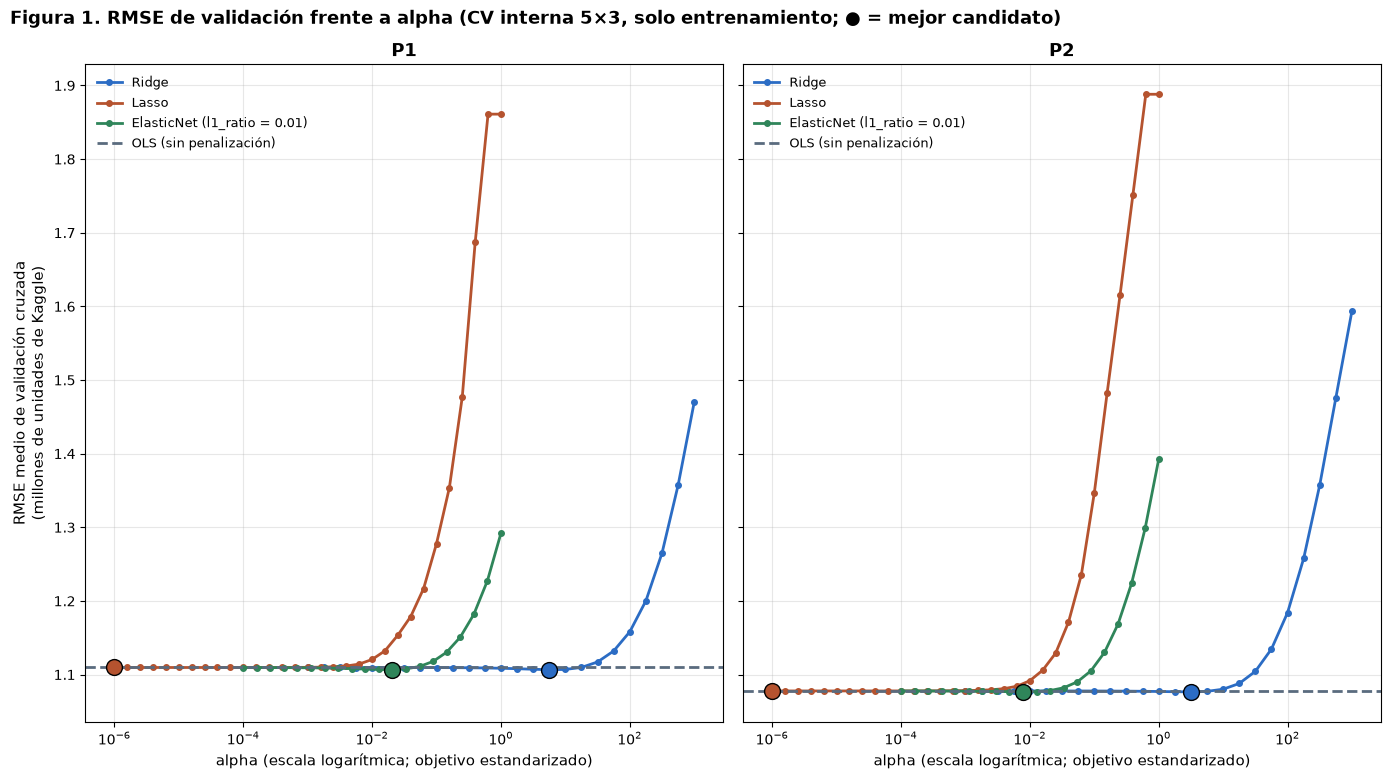

In [11]:
COLOR = {"OLS": "#5A6B7E", "Ridge": "#2B6CC4", "Lasso": "#B5532F", "ElasticNet": "#2F855A"}
fig, ejes = plt.subplots(1, len(PREPROCESAMIENTOS_T19), figsize=(14, 7.9), sharey=True, squeeze=False)
for ax, p in zip(ejes[0], PREPROCESAMIENTOS_T19):
    for nombre in ("Ridge", "Lasso", "ElasticNet"):
        c = candidatos[(candidatos["preprocesamiento"] == p) & (candidatos["modelo"] == nombre)].copy()
        c["alpha"] = c["hiperparametros"].map(lambda s: json.loads(s)["alpha"])
        if nombre == "ElasticNet":
            mejor_l1 = json.loads(resultados[(resultados["preprocesamiento"] == p) & (resultados["modelo"] == nombre)].iloc[0]["hiperparametros_seleccionados"])["l1_ratio"]
            c = c[c["hiperparametros"].map(lambda s: json.loads(s)["l1_ratio"]) == mejor_l1]
            etiqueta = f"ElasticNet (l1_ratio = {mejor_l1})"
        else:
            etiqueta = nombre
        c = c.sort_values("alpha")
        ax.plot(c["alpha"], c["rmse_media"] / 1e6, marker="o", ms=4, lw=2, color=COLOR[nombre], label=etiqueta)
        k = c["rmse_media"].idxmin()
        ax.scatter(c.loc[k, "alpha"], c.loc[k, "rmse_media"] / 1e6, s=130, color=COLOR[nombre], edgecolor="black", zorder=5)
    ols = resultados[(resultados["preprocesamiento"] == p) & (resultados["modelo"] == "OLS")]["rmse_media"].iloc[0] / 1e6
    ax.axhline(ols, color=COLOR["OLS"], ls="--", lw=2, label="OLS (sin penalización)")
    ax.set_xscale("log")
    ax.set_title(f"{p}", fontsize=13, fontweight="bold")
    ax.set_xlabel("alpha (escala logarítmica; objetivo estandarizado)", fontsize=11)
    ax.grid(alpha=0.3)
    ax.legend(frameon=False, fontsize=9, loc="upper left")
ejes[0][0].set_ylabel("RMSE medio de validación cruzada\n(millones de unidades de Kaggle)", fontsize=11)
fig.suptitle("Figura 1. RMSE de validación frente a alpha (CV interna 5×3, solo entrenamiento; ● = mejor candidato)", fontsize=13, fontweight="bold", x=0.01, ha="left")
fig.tight_layout()
fig.savefig(DIR_FIGURAS / "fig_t19_rmse_vs_alpha.png", dpi=200, bbox_inches="tight")
plt.show()

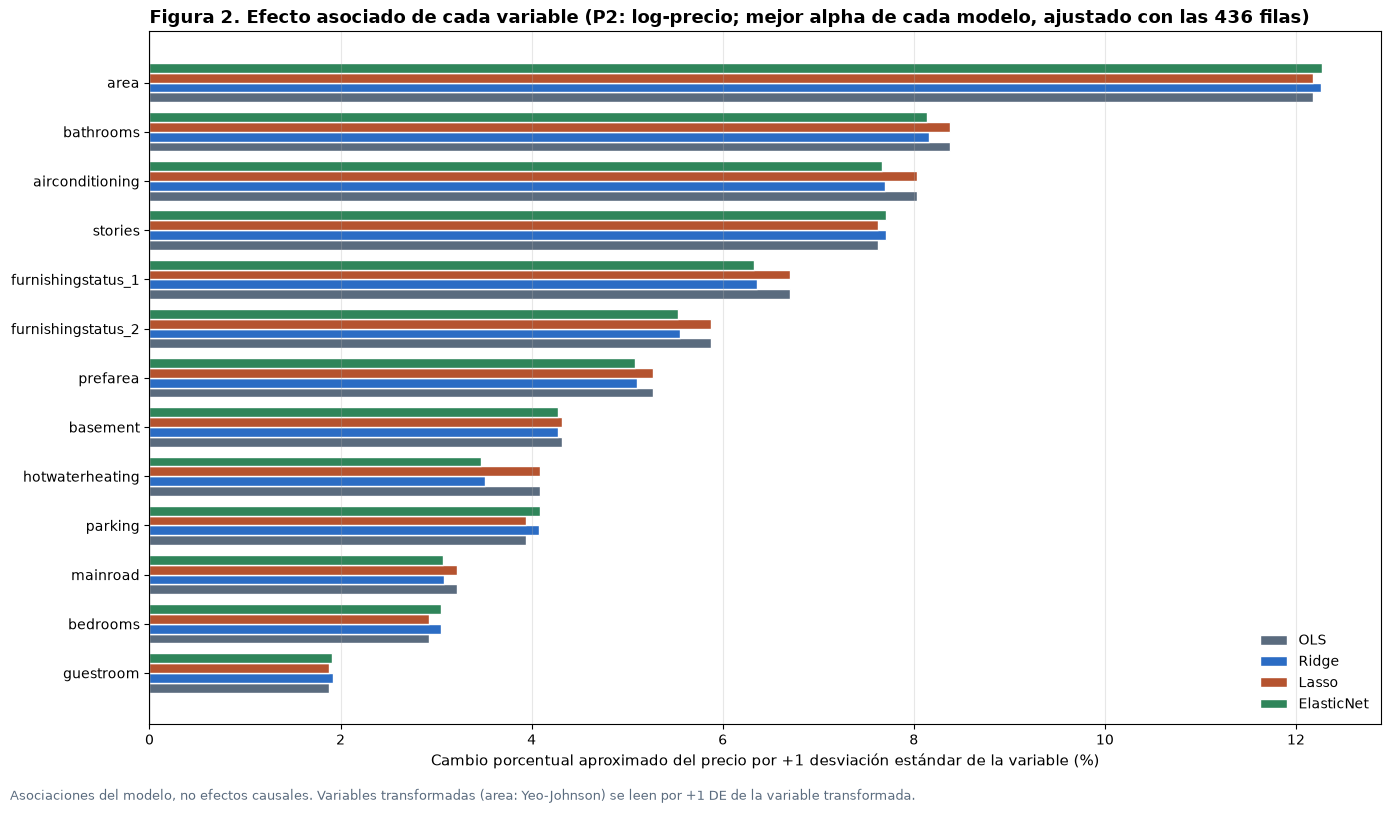

In [12]:
# Figura 2: efecto de +1 DE de cada variable en el precio (%), P2, cuatro modelos
c2 = coeficientes[coeficientes["preprocesamiento"] == "P2"].copy()
orden = c2[c2["modelo"] == "OLS"].sort_values("efecto_1DE_pct")["variable"].tolist()
fig, ax = plt.subplots(figsize=(14, 7.9))
alto = 0.2
for i, nombre in enumerate(MODELOS_LINEALES):
    s = c2[c2["modelo"] == nombre].set_index("variable").loc[orden]
    ax.barh(np.arange(len(orden)) + (i - 1.5) * alto, s["efecto_1DE_pct"], height=alto, color=COLOR[nombre], label=nombre, edgecolor="white")
ax.set_yticks(np.arange(len(orden)))
ax.set_yticklabels(orden, fontsize=10)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Cambio porcentual aproximado del precio por +1 desviación estándar de la variable (%)", fontsize=11)
ax.set_title("Figura 2. Efecto asociado de cada variable (P2: log-precio; mejor alpha de cada modelo, ajustado con las 436 filas)", fontsize=13, fontweight="bold", loc="left")
ax.grid(axis="x", alpha=0.3)
ax.legend(frameon=False, loc="lower right")
fig.text(0.01, -0.02, "Asociaciones del modelo, no efectos causales. Variables transformadas (area: Yeo-Johnson) se leen por +1 DE de la variable transformada.", fontsize=9.5, color="#5A6B7E")
fig.tight_layout()
fig.savefig(DIR_FIGURAS / "fig_t19_coeficientes_p2.png", dpi=200, bbox_inches="tight")
plt.show()

## 9. Interpretación de los coeficientes

**Cómo se leen.** En **P2** el objetivo es `log(precio)`: un coeficiente `β` de una variable con escala natural aproxima un cambio porcentual del precio de `100·(exp(β) − 1)` % por unidad. En **P1** el objetivo está en la escala original: `β` es el cambio del precio (unidades de Kaggle; ÷ 70 para CAD de 1987) por unidad. Como las variables tienen escalas distintas, las tablas muestran el **efecto de +1 desviación estándar** (`efecto_1DE`), que sí permite compararlas entre sí; `coef_modelo` solo se compara entre variables con la misma escala.

**Qué no significan.** Son asociaciones condicionales del modelo con estos 436 datos de Windsor de 1987, no efectos causales. Con atributos correlacionados (`area`, `bedrooms`, `bathrooms`), Lasso y ElasticNet pueden anular una variable y conservar otra casi equivalente, y la elección cambia con la muestra; Ridge reparte el efecto entre ellas. El retorno a la escala original solo afecta a las **métricas** (que ya salen en precio), no a la lectura de los coeficientes en log.

In [13]:
# Variables más asociadas con el precio (P2, OLS y el mejor modelo penalizado) y estabilidad de la selección
mejor_pen = resultados[(resultados["preprocesamiento"] == "P2") & (resultados["modelo"] != "OLS")].iloc[0]["modelo"]
p2 = coeficientes[(coeficientes["preprocesamiento"] == "P2") & coeficientes["modelo"].isin(["OLS", mejor_pen])]
tabla_i = p2.pivot(index="variable", columns="modelo", values="efecto_1DE_pct").round(2)
tabla_i["|efecto| OLS"] = tabla_i["OLS"].abs()
tabla_i = tabla_i.sort_values("|efecto| OLS", ascending=False).drop(columns="|efecto| OLS")
display(Markdown(f"**Efecto (%) del precio por +1 DE, P2.** Columnas: OLS y el modelo penalizado con menor RMSE en P2 (**{mejor_pen}**). Ordenado por tamaño del efecto en OLS."))
display(tabla_i)

nulos = coeficientes[(coeficientes["modelo"].isin(["Lasso", "ElasticNet"]))].groupby(["preprocesamiento", "modelo"])["coef_nulo"].agg(["sum", "count"]).rename(columns={"sum": "coeficientes en 0", "count": "variables"})
display(Markdown("**Coeficientes llevados exactamente a 0 por la penalización L1:**"))
nulos

**Efecto (%) del precio por +1 DE, P2.** Columnas: OLS y el modelo penalizado con menor RMSE en P2 (**Ridge**). Ordenado por tamaño del efecto en OLS.

modelo,OLS,Ridge
variable,,
area,12.18,12.27
bathrooms,8.38,8.16
airconditioning,8.03,7.69
stories,7.63,7.71
furnishingstatus_1,6.70,6.36
furnishingstatus_2,5.87,5.56
prefarea,5.27,5.10
basement,4.32,4.28
hotwaterheating,4.09,3.51


**Coeficientes llevados exactamente a 0 por la penalización L1:**

coeficientes en 0  variables
preprocesamiento modelo                                  
P1               ElasticNet                  0         13
                 Lasso                       0         13
P2               ElasticNet                  0         13
                 Lasso                       0         13

In [14]:
nombres_nulos = coeficientes[coeficientes["coef_nulo"] & coeficientes["modelo"].isin(["Lasso", "ElasticNet"])][["preprocesamiento", "modelo", "variable"]]
nombres_nulos if len(nombres_nulos) else pd.DataFrame({"resultado": ["Ningún coeficiente quedó en 0 con el alpha seleccionado"]})

,resultado
0,Ningún coeficiente quedó en 0 con el alpha sel...


## 10. Limitaciones

- **Resultados de desarrollo, optimistas.** Se seleccionó el mejor `alpha` con los mismos 15 pliegues con que se informa el error. La estimación sin ese sesgo es la validación anidada de T22.
- **Sin pruebas estadísticas entre modelos.** Las medias y desviaciones entre pliegues describen variabilidad; los pliegues repetidos no son independientes. La prueba t corregida y Holm son de T22.
- **P3 no evaluado** (pendiente de la corrección de Mauricio; no se implementó una versión propia).
- **Muestra pequeña** (436 filas de entrenamiento): coeficientes inestables con atributos correlacionados.
- **Datos históricos y escalados.** Windsor, 1987; `price` de Kaggle = CAD 1987 × 70. Nada se interpreta como precio actual ni colombiano.
- **Retransformación de `log(price)`** (P2): la predicción tiende a la mediana condicional; no se aplicó la corrección de *smearing*.
- **Asociación, no causalidad.** `furnishingstatus` fue agregada en Kaggle sin documentar su origen.
- **Test sellado sin usar.** Esto no es rendimiento final.

## 11. Conclusiones de desarrollo

Las cifras se calculan desde las tablas de este notebook; la lectura es descriptiva y **no declara un ganador**.

In [15]:
f = lambda v: f"{v:,.0f}"
r = resultados.set_index(["preprocesamiento", "modelo"])
lineas = []
b = resultados.iloc[0]
lineas.append(f"**Menor RMSE medio de validación:** {b['modelo']} con {b['preprocesamiento']} ({f(b['rmse_media'])} ± {f(b['rmse_desv'])} unidades de Kaggle ≈ {f(b['rmse_cad1987_media'])} CAD de 1987; MAPE {b['mape_media']:.2f} %; R² {b['r2_media']:.3f}); hiperparámetros: `{b['hiperparametros_seleccionados']}`.")

for p in PREPROCESAMIENTOS_T19:
    base = r.loc[(p, "OLS"), "rmse_media"]
    partes = []
    for nombre in ("Ridge", "Lasso", "ElasticNet"):
        v = r.loc[(p, nombre), "rmse_media"]
        partes.append(f"{nombre} {f(v)} ({(v - base) / base * 100:+.2f} %)")
    lineas.append(f"**{p}:** OLS = {f(base)}; " + "; ".join(partes) + ". Diferencias respecto de OLS pequeñas frente a la desviación entre pliegues (" + f"{f(r.loc[(p, 'OLS'), 'rmse_desv'])})" + (": la penalización aporta poco en este diseño." if max(abs(r.loc[(p, n), 'rmse_media'] - base) for n in ('Ridge', 'Lasso', 'ElasticNet')) < r.loc[(p, 'OLS'), 'rmse_desv'] else "."))

ef = []
for nombre in MODELOS_LINEALES:
    a, b2 = r.loc[("P1", nombre)], r.loc[("P2", nombre)]
    ef.append(f"{nombre}: RMSE {(b2['rmse_media'] - a['rmse_media']) / a['rmse_media'] * 100:+.1f} %, MAPE {b2['mape_media'] - a['mape_media']:+.2f} pp")
lineas.append("**P2 frente a P1 (cambio relativo del RMSE y diferencia del MAPE):** " + "; ".join(ef) + ". Es una lectura descriptiva sobre H2; la contrasta T17–T18 con los mismos pliegues.")

mejores_p = resultados.groupby("preprocesamiento").first()
mejor_modelo_p = resultados[resultados["modelo"] == "OLS"].set_index("preprocesamiento")["rmse_media"]
n_mejor_ols = {p: int((per_fold[(p, resultados[resultados['preprocesamiento'] == p].iloc[0]['modelo'])] < per_fold[(p, 'OLS')]).sum()) for p in PREPROCESAMIENTOS_T19}
lineas.append("**Conteo descriptivo por pliegue (no es una prueba):** el mejor modelo de cada preprocesamiento tiene menor RMSE que OLS en " + "; ".join(f"{n} de 15 pliegues con {p}" for p, n in n_mejor_ols.items()) + ".")
bordes = resultados[resultados["parametros_en_borde_de_rejilla"].fillna("") != ""][["preprocesamiento", "modelo", "parametros_en_borde_de_rejilla"]]
if len(bordes):
    lineas.append("**Hiperparámetros en el borde de la rejilla:** " + "; ".join(f"{fila.modelo} con {fila.preprocesamiento} ()" for fila in bordes.itertuples())
                  + ". Lasso eligió el menor  probado (1e-6), es decir, prácticamente OLS: la selección L1 no mejora el error de validación. ElasticNet eligió el menor  (0,01), es decir, una penalización casi solo L2 (Ridge); ampliar la rejilla en esa dirección converge a Ridge.")
lineas.append("**Convergencia:** Lasso y ElasticNet convergieron en todos los casos (sin avisos y con iteraciones muy por debajo del tope).")
display(Markdown("\n\n".join(f"- {l}" for l in lineas)))

- **Menor RMSE medio de validación:** Ridge con P2 (1,076,577 ± 129,653 unidades de Kaggle ≈ 15,380 CAD de 1987; MAPE 16.61 %; R² 0.663); hiperparámetros: `{"alpha": 3.1622776601683795}`.

- **P1:** OLS = 1,109,629; Ridge 1,106,642 (-0.27 %); Lasso 1,109,630 (+0.00 %); ElasticNet 1,106,791 (-0.26 %). Diferencias respecto de OLS pequeñas frente a la desviación entre pliegues (141,567): la penalización aporta poco en este diseño.

- **P2:** OLS = 1,077,789; Ridge 1,076,577 (-0.11 %); Lasso 1,077,790 (+0.00 %); ElasticNet 1,076,641 (-0.11 %). Diferencias respecto de OLS pequeñas frente a la desviación entre pliegues (131,977): la penalización aporta poco en este diseño.

- **P2 frente a P1 (cambio relativo del RMSE y diferencia del MAPE):** OLS: RMSE -2.9 %, MAPE -1.48 pp; Ridge: RMSE -2.7 %, MAPE -1.43 pp; Lasso: RMSE -2.9 %, MAPE -1.48 pp; ElasticNet: RMSE -2.7 %, MAPE -1.40 pp. Es una lectura descriptiva sobre H2; la contrasta T17–T18 con los mismos pliegues.

- **Conteo descriptivo por pliegue (no es una prueba):** el mejor modelo de cada preprocesamiento tiene menor RMSE que OLS en 8 de 15 pliegues con P1; 4 de 15 pliegues con P2.

- **Hiperparámetros en el borde de la rejilla:** ElasticNet con P2 (); Lasso con P2 (); ElasticNet con P1 (); Lasso con P1 (). Lasso eligió el menor  probado (1e-6), es decir, prácticamente OLS: la selección L1 no mejora el error de validación. ElasticNet eligió el menor  (0,01), es decir, una penalización casi solo L2 (Ridge); ampliar la rejilla en esa dirección converge a Ridge.

- **Convergencia:** Lasso y ElasticNet convergieron en todos los casos (sin avisos y con iteraciones muy por debajo del tope).

**Qué queda para las fases siguientes.** Evaluar P3 cuando Mauricio integre la corrección en `main`; comparar estos modelos con KNN/SVR (T20) y ensambles (T21) con la **validación anidada de T22**, con pruebas t corregidas y Holm; y evaluar una sola vez en el test sellado (T25).

## 12. Reproducción

Se verifica que los datos no cambiaron y que repetir una búsqueda (Ridge, P2) da exactamente el mismo mejor candidato y las mismas métricas.

In [16]:
assert huella_sha256(RUTA_DATOS_CRUDOS) == SHA256_DATOS_CRUDOS
_, _, ev2 = cargar_entrenamiento()
assert ev2["sha256_particion"] == evidencia["sha256_particion"] and ev2["sha256_housing_limpio"] == evidencia["sha256_housing_limpio"]

r2 = ejecutar_busqueda(construir_pipeline_lineal("P2", "Ridge"), ESPACIOS["Ridge"], X, y, crear_pliegues(y), tipo="grid", n_jobs=1)
fila_1 = resultados[(resultados["preprocesamiento"] == "P2") & (resultados["modelo"] == "Ridge")].iloc[0]
fila_2 = fila_mejor(r2["busqueda"], "P2", "Ridge", r2["duracion_s"], r2["n_candidatos"])
assert fila_1["hiperparametros_seleccionados"] == fila_2["hiperparametros_seleccionados"]
assert abs(fila_1["rmse_media"] - fila_2["rmse_media"]) == 0.0
print("Reproducible: mismo mejor candidato y mismas métricas en una segunda ejecución.")

Reproducible: mismo mejor candidato y mismas métricas en una segunda ejecución.


**Cómo repetirlo.** Desde la raíz del repositorio, con `requirements.txt`: *Kernel → Restart & Run All* (en Colab, ejecutar la primera celda). Las pruebas automáticas están en `tests/test_modelos_lineales.py` (`python -m pytest tests/test_modelos_lineales.py`). Salidas: `reports/tables/t19_resultados.csv`, `t19_busqueda_hiperparametros.csv`, `t19_coeficientes.csv`, `t19_ols_hedonico_inferencia.csv`, `t19_entorno.json` y las figuras `fig_t19_rmse_vs_alpha.png` y `fig_t19_coeficientes_p2.png`.

**Evidencia de que el test sellado no se usó.** `cargar_entrenamiento()` deja `n_prueba_cargado = 0`; las huellas SHA-256 de `particion.csv` y `housing_limpio.csv` coinciden al inicio y al final; todos los pliegues se construyen sobre los 436 índices de entrenamiento.